# Exemple 8 : handling CMIP6 climate projection NetCDF files and running yield simulations for multiple years - North Cameroon 2030-2040

The aim of this notebook is to provide a full working example of simulation performed using data provided in NetCDF format ; this example covers Northern Cameroon.

## Imports

In [ ]:
import numpy as np
import datetime
from matplotlib import pyplot as plt
from tqdm import tqdm as tqdm
import xarray as xr
from sarra_py import *
from sarra_py import ModelParameters, SimulationConfig, load_model_parameters, run_simulation as run_sarra_simulation, select_daily_window, validate_input_dataset
import geopandas as gpd

## 1. Defining simulation dates

We begin by defining two key parameters for the simulation: `date_start` and `duration`.

- **`date_start`**: The start date of the simulation. This defines the first day for which data will be loaded and marks the beginning of daily water balance computations. It is recommended to set this date approximately one month before the expected sowing date. This allows the water balance to stabilize before the effective sowing date, which is critical since the emergence phase is triggered by a specific level of soil moisture.

- **`duration`**: The length of the simulation in days. This parameter specifies the number of daily cycles after `date_start` during which computations will run. It determines the time range covered by the simulation and sets the size of the time dimension in the computation arrays. Only the days within the interval `[date_start, date_start + duration]` will be used for calculations.


In [292]:
# date_start = datetime.date(2030,4,1)
# duration = 250

## 1. Preparing the base dataset (`base_data`)

For this example, we will use CMIP6 climate projection data for Northern Cameroon between 2030 and 2040, as provided in NetCDF format by the Climate Data Store ; we will use the cnrm_cm6_1_hr model under the ssp5_8_5 scenario. We will provide the NetCDF files but provide commented code below to pass requests to get these data using the CDSAPI tool. 

In [ ]:
# The four NetCDF files used below are already included locally.
# To acquire another collection, download it separately and update the paths in the next cell.
from pathlib import Path
netcdf_dir = Path("../data/exemple_data/exemple_8")
if not netcdf_dir.exists() or len(list(netcdf_dir.glob("*.nc"))) < 4:
    raise FileNotFoundError(
        "Expected four local climate NetCDF files in ../data/exemple_data/exemple_8"
    )
print(f"Using local climate files in {netcdf_dir}")


Once the datasets are unzipped, we define the paths to the rainfall and climate variables NetCDF files.

  - `Tmin`: Daily maximum temperature (°C)
  - `Tmax`: Daily minimum temperature (°C)
  - `Tmean`: Daily mean temperature (°C)
  - `rainfall` : Daily rainfall (mm)

The spatial extent of the rainfall dataset determines the spatial coverage of the simulation, ensuring that all computations align with the specified geographic area.

In [247]:
# defining the path to the NetCDF datasets
rainfall_data_path = "../data/exemple_data/exemple_8/pr_day_CNRM-CM6-1-HR_ssp585_r1i1p1f2_gr_20300101-20401231.nc"
tmax_data_path = "../data/exemple_data/exemple_8/tasmax_day_CNRM-CM6-1-HR_ssp585_r1i1p1f2_gr_20300101-20401231.nc"
tmin_data_path = "../data/exemple_data/exemple_8/tasmin_day_CNRM-CM6-1-HR_ssp585_r1i1p1f2_gr_20300101-20401231.nc"
tmean_data_path = "../data/exemple_data/exemple_8/tas_day_CNRM-CM6-1-HR_ssp585_r1i1p1f2_gr_20300101-20401231.nc"

Next, we determine the dimensions of the gridded rainfall dataset. In SARRA-Py, the spatial resolution of the simulation is determined by the resolution of the rainfall dataset. This ensures that all calculations are aligned with the same grid structure, maintaining consistency across the simulation.

Finally, we initialize the base xarray dataset, and load the rainfall and climate data. Here and contrary to other example notebooks, we do not rely on the helper functions load_TAMSAT_data and load_AgERA5_data, as the latter were taylored to load datasets as GeoTIFFs series. Thus, we use raw xarray functions to manage the loading of the provided NetCDF datasets.

In [ ]:
def run_for_year(year):

        date_start = datetime.date(year,4,1)
        duration = 250

        # We load the netCDF file for rainfall in order to get the size of the computational grid.
        rainfall_data = xr.open_dataset(rainfall_data_path)
        grid_width, grid_height = rainfall_data.dims['lat'], rainfall_data.dims['lon']
        print("The grid is {} pixels wide by {} pixels high.".format(grid_width, grid_height))

        # initialize empty xarray dataset
        base_data = xr.Dataset()

        # Loading the rainfall variable
        # Loading rainfall data NetCDF, and subsetting to the dates we need
        rainfall_data = select_daily_window(rainfall_data["pr"], date_start, duration)
        rainfall_data = rainfall_data * 86400 # converting from m3/s to mm/d
        # We put this data into the base_data dataarray, and apply the standard attributes
        base_data["rain"] = rainfall_data
        base_data["rain"].attrs = {"units":"mm", "long_name":"rainfall"}


        # Loading the weather variables
        # Lading Tmin and Tmax data NetCDF, also applying transposition, and subsetting to the dates we need
        tmax_data = xr.open_dataset(tmax_data_path)
        tmax_data = select_daily_window(tmax_data["tasmax"], date_start, duration)
        tmax_data = tmax_data - 273.15 # converting from Kelvin to °C
        tmin_data = xr.open_dataset(tmin_data_path)
        tmin_data = select_daily_window(tmin_data["tasmin"], date_start, duration)
        tmin_data = tmin_data - 273.15 # converting from Kelvin to °C

        # # calculating the mean temperature, and putting it into the base_data dataarray
        tmean_data = xr.open_dataset(tmean_data_path)
        tmean_data = select_daily_window(tmean_data["tas"], date_start, duration)
        tmean_data = tmean_data -  273.15
        base_data["tpMoy"] = tmean_data


        # calculating extraterrestrial 
        phi = np.deg2rad(base_data.lat) # latitudes en rad
        doy = tmax_data.time.dt.dayofyear # jour de l’année (1-365)
        dr = 1 + 0.033 * np.cos(2*np.pi/365 * doy)
        delta  = 0.409 * np.sin(2*np.pi/365 * doy - 1.39)
        omega_s = np.arccos(-np.tan(phi) * np.tan(delta))
        Ra = (24*60/np.pi) * 0.0820 * dr * (
                omega_s*np.sin(phi)*np.sin(delta) + np.cos(phi)*np.cos(delta)*np.sin(omega_s)
        )                    # dims : (time, lat)

        # on réplique Ra sur toutes les longitudes pour avoir (time, lat, lon)
        Ra = Ra.expand_dims(lon=base_data.lon).transpose('time', 'lat', 'lon')

        # Radiation solaire à partir de la température (en MJ/m2/j)
        base_data["rg"] = 0.16 * Ra * (tmax_data - tmin_data)**0.5

        # calcul de ET0 selon la formule de Hargraeves
        base_data["ET0"] = 0.0023 * (tmean_data + 17.8) * np.sqrt(tmax_data - tmin_data) * Ra
        base_data["ET0"].attrs = {"units": "mm d-1", "long_name": "ET0 – Hargreaves"}

        # All the loadings of these files was facilitated by the fact that they were already at the good units and homogeneous spatial projections and dimensions.




        # Now, we prepare the soil properties dataset. Here, we also cannot rely on the helper function load_iSDA_soil_data as
        # it was destined to load data for the African continent (using iSDA Africa datasets).
        # Here, we then replace this function call with a manual construction of dummy variables for soil
        # properties in Brazil (i.e. the whole country will have homogeneous soil properties), for the purpose of testing. 

        # We initialize all the necessary variables with dummy values
        # Estimated soil properties from Brazil should be loaded here to get a more realistic simulation.

        # profile depth, 500 mm
        # here we take the first time step of the rainfall data as reference ot get the correct dimensions
        base_data["profRu"] = 500.0 * xr.ones_like(base_data["rain"][0,:,:]) 
        base_data["profRu"].attrs = {"units": "mm", "long_name": "Soil root zone depth (mm)"}

        # soil surface reservoir depth, 100 mm
        # then, we use profRu as a reference for the dimensions of invariant variables
        base_data["epaisseurSurf"] = 100.0 * xr.ones_like(base_data["profRu"])
        base_data["epaisseurSurf"].attrs = {"units": "mm", "long_name": "Soil surface reservoir depth (mm)"}

        # initial water stock in the soil surface reservoir, 50 mm (that sounds a lot)
        base_data["stockIniProf"] = 50.0 * xr.ones_like(base_data["profRu"])
        base_data["stockIniProf"].attrs = {"units": "mm", "long_name": "Initial water stock in the deep surface reservoir (mm)"}

        # runoff rate, 10%
        base_data["runoff_rate"] = 0.1 * xr.ones_like(base_data["profRu"])
        base_data["runoff_rate"].attrs = {"units": "mm", "long_name": "Runoff rate (mm)"}

        # runoff threshold, 10 mm 
        base_data["runoff_threshold"] = 10.0 * xr.ones_like(base_data["profRu"])

        # RZPAWC, root zone plant available water capacity, 100 mm
        base_data["RZPAWC"] = 100.0 * xr.ones_like(base_data["profRu"])
        base_data["RZPAWC"].attrs = {"units": "mm", "long_name": "Root zone plant available water capacity (mm)"}

        base_data["ru"] = base_data["RZPAWC"] / (base_data["profRu"]/1000)
        base_data["ru"].attrs = {"units": "mm", "long_name": "Root zone plant available water (mm)"}

        # Complete the homogeneous demonstration profile.
        base_data["epaisseurProf"] = base_data["profRu"] - base_data["epaisseurSurf"]
        base_data["stockIniSurf"] = xr.zeros_like(base_data["profRu"])




        # Finally, we compute the day length, which is independent of parameters (and thus needs to be in the base dataset), and is needed in computations.
        base_data = base_data.rename({'lat': 'y', 'lon': 'x'})
        # compute day length raster
        base_data = calc_day_length_raster_fast(base_data, date_start, duration)


        # As we see below, the resulting base dataset is a `xarray.Dataset` object, which contains the rainfall and climate data, as well as the soil parameters. It also contains the day length, which is computed from the latitude of the location.


        # parameter file names (files are located in the ../data/parameters/ folder)
        file_paramVariete = "variety_exemple_2.yaml"
        file_paramITK = "itk_exemple_2.yaml"
        file_paramTypeSol = "USA_iowa_V42.yaml"

        # populate param variables with variety, cropping system and soil parameters
        parameters = load_model_parameters(
            f"../data/params/variety/{file_paramVariete}",
            f"../data/params/itk/{file_paramITK}",
            f"../data/params/soil/{file_paramTypeSol}",
        )
        paramVariete = dict(parameters.variety)
        paramITK = dict(parameters.management)
        paramTypeSol = dict(parameters.soil)

        # we will force a value for the sowing date, so that we do not need to update the example file
        paramITK["DateSemis"] = datetime.date(year,5,1)

        # on force les paramètres optimisés
        paramVariete["SDJRPR"] = 489.0
        paramVariete["SDJLevee"] = 250.0
        paramVariete["SDJBVP"] = 636.0
        paramVariete["slaMin"] = 285.0
        paramVariete["slaMax"] = 363.2
        paramVariete["SDJMatu1"] = 848.0
        paramVariete["SDJMatu2"] = 334.0
        paramVariete["KRdtPotA"] = 0.9



        data = run_sarra_simulation(
            base_data, ModelParameters(paramVariete, paramITK, paramTypeSol),
            SimulationConfig(date_start, duration),
        )

        return data



In [259]:
from joblib import Parallel, delayed

years = range(year_min, year_max+1)
results = Parallel(n_jobs=-1, prefer="processes")(delayed(run_for_year)(year) for year in years)
results_dict = dict(zip(years, results))

/tmp/ipykernel_1325/130196390.py:8: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
/tmp/ipykernel_1325/130196390.py:8: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
/tmp/ipykernel_1325/130196390.py:8: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
/tmp/ipykernel_1325/130196390.py:8: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in orde

The grid is 12 pixels wide by 8 pixels high.The grid is 12 pixels wide by 8 pixels high.

The grid is 12 pixels wide by 8 pixels high.
The grid is 12 pixels wide by 8 pixels high.The grid is 12 pixels wide by 8 pixels high.

The grid is 12 pixels wide by 8 pixels high.
The grid is 12 pixels wide by 8 pixels high.
The grid is 12 pixels wide by 8 pixels high.


/tmp/ipykernel_1325/130196390.py:146: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
/tmp/ipykernel_1325/130196390.py:146: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
/tmp/ipykernel_1325/130196390.py:146: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
  0%|          | 0/250 [00:00<?, ?it/s]/tmp/ipykernel_1325/130196390.py:146: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
/tmp/ipykernel_1325/130196390.py:146: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
 89%|████████▉ | 223/250 [02:49<00:17,  1.58it/s]/tmp/ipykernel_1325/130196390.py:8: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.


The grid is 12 pixels wide by 8 pixels high.


 94%|█████████▍| 235/250 [02:54<00:15,  1.06s/it]/tmp/ipykernel_1325/130196390.py:8: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.


The grid is 12 pixels wide by 8 pixels high.


  5%|▌         | 13/250 [00:10<02:57,  1.34it/s]

The grid is 12 pixels wide by 8 pixels high.


100%|██████████| 250/250 [01:42<00:00,  2.45it/s]


In [285]:
import xarray as xr

# results → liste déjà triée dans le même ordre que `years`
years = range(year_min, year_max + 1)

last_rdt_per_year = [
    ds["rdt"].isel(time=-1)                               # DataArray (sans la boucle temporelle)
      .expand_dims(                                       # on remet une dim "time" de longueur 1
          time=[ds["time"].isel(time=-1).values]          # → coordonnée = vrai datetime
      )
    for ds in results                                     # results = liste de xr.Dataset
]

rdt_last = xr.concat(last_rdt_per_year, dim="time")       # DataArray final

rdt_last_ds = rdt_last.to_dataset(name="rdt")

In [286]:
# years explicitement issus de tes bornes
years = np.arange(year_min, year_max + 1)   # ex. [2030, 2031, …, 2040]

# --- DataArray : la coordonnée "time" devient la suite des années ----------
rdt_year = (
    rdt_last
      .assign_coords(time=("time", years.astype("int32")))  # change les valeurs
      .rename(time="year")                                  # facultatif, plus clair
)

# --- Dataset optionnel ------------------------------------------------------
rdt_year_ds = rdt_year.to_dataset(name="rdt")

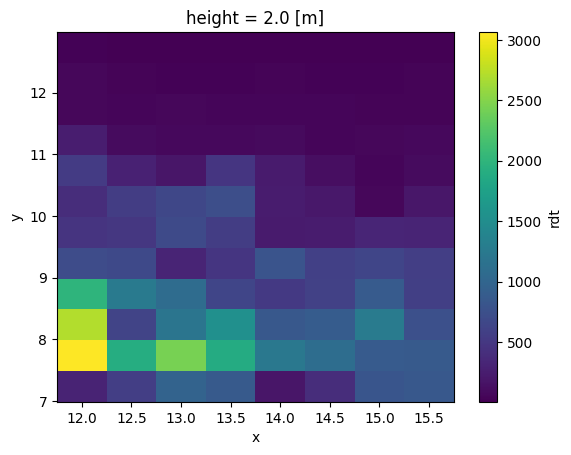

In [277]:
rdt_last_ds["rdt"].mean(dim="time").plot()

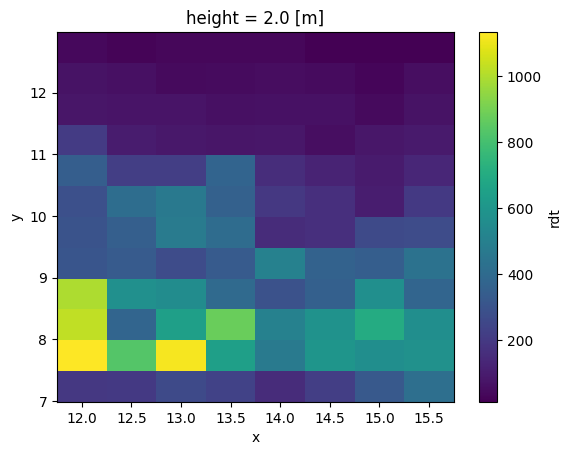

In [273]:
rdt_last_ds["rdt"].std(dim="time").plot()

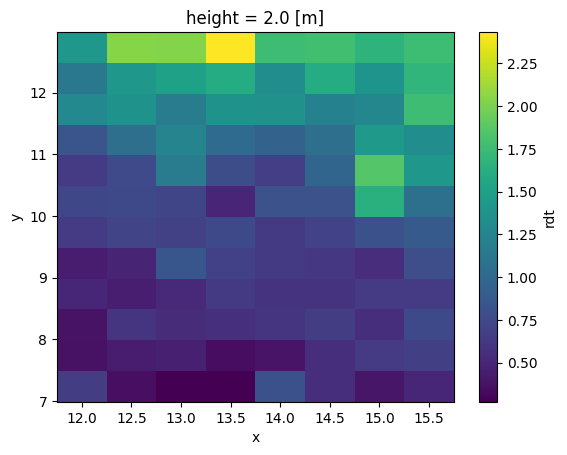

In [270]:
(rdt_last_ds.std(dim="time")["rdt"] / rdt_last_ds.mean(dim="time")["rdt"]).plot()

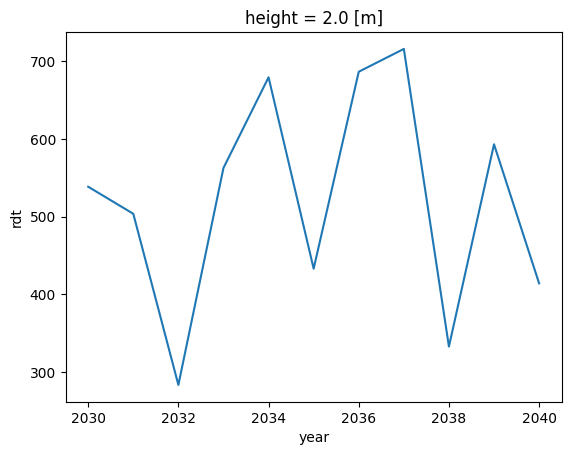

In [289]:
rdt_year_ds["rdt"].mean(dim=["y","x"]).plot()

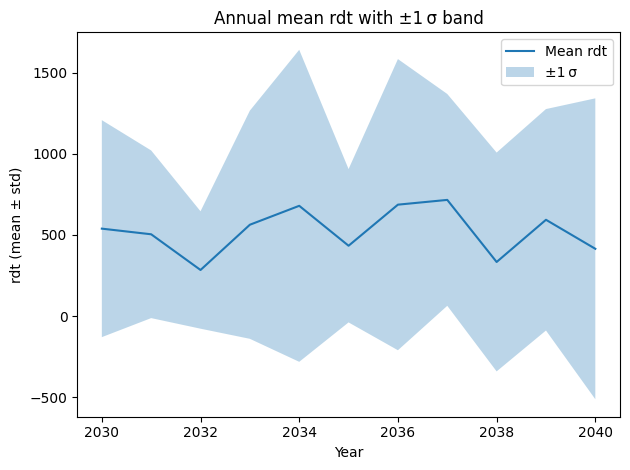

In [290]:
import matplotlib.pyplot as plt

# Assume `rdt_year_ds` is already in the notebook environment
# Compute mean and standard deviation over the spatial dimensions
mean_rdt = rdt_year_ds["rdt"].mean(dim=["y", "x"])
std_rdt  = rdt_year_ds["rdt"].std(dim=["y", "x"])

years = mean_rdt["year"].values

# Create the plot
plt.figure()
plt.plot(years, mean_rdt.values, label="Mean rdt")
plt.fill_between(years,
                 (mean_rdt - std_rdt).values,
                 (mean_rdt + std_rdt).values,
                 alpha=0.3,
                 label="±1 σ")

plt.xlabel("Year")
plt.ylabel("rdt (mean ± std)")
plt.title("Annual mean rdt with ±1 σ band")
plt.legend()
plt.tight_layout()
plt.show()


## 3. Preparing a simulation dataset (`data`)

In this section, we will be loading simulation-specific parameters, and preparing a simulation dataset accordingly.

First, we will load the variety parameters file (`file_paramVariete`), the agricultural itinerary parameters file (`file_paramITK`) as well as the soil parameters file (`file_paramTypeSol`) by calling the `load_YAML_parameters` function. All these files can be found commented in the `./data/params/` folder. We incite you to make copies of the provided examples and play around with parameters by calling your copies.

In [ ]:
# # parameter file names (files are located in the ../data/parameters/ folder)
# file_paramVariete = "variety_exemple_2.yaml"
# file_paramITK = "itk_exemple_2.yaml"
# file_paramTypeSol = "USA_iowa_V42.yaml"

# # populate param variables with variety, cropping system and soil parameters
# paramVariete, paramITK, paramTypeSol = load_YAML_parameters(file_paramVariete, file_paramITK, file_paramTypeSol)

# # we will force a value for the sowing date, so that we do not need to update the example file
# paramITK["DateSemis"] = datetime.date(2030,5,1)

# # on force les paramètres optimisés
# paramVariete["SDJRPR"] = 489.0
# paramVariete["SDJLevee"] = 250.0
# paramVariete["SDJBVP"] = 636.0
# paramVariete["slaMin"] = 285.0
# paramVariete["slaMax"] = 363.2
# paramVariete["SDJMatu1"] = 848.0
# paramVariete["SDJMatu2"] = 334.0
# paramVariete["KRdtPotA"] = 0.9








Once the parameters are loaded, we build up the simulation dataset `data` by copying the base dataset `base_data`, and feeding it with the simulation-specific parameters.

In [ ]:
# # creating simulation xarray dataset `data` by copying the base data
# data = base_data.copy()

# # initializing all the necessary variables
# data = initialize_simulation(data, grid_width, grid_height, duration, paramVariete, paramITK, date_start)
# data = initialize_default_irrigation(data)
# data = calculate_once_daily_thermal_time(data, paramVariete)

In [ ]:
# dropping the coordinates from the time dimension as computations are performed using int indices
# data = data.drop("time")

/tmp/ipykernel_1325/3342873258.py:2: DeprecationWarning: dropping variables using `drop` is deprecated; use drop_vars.
  data = data.drop("time")


The resulting dataset `data` is a `xarray.Dataset` object, which contains all initialized variables for computations.

## 4. Running the model

Once the dataset is built, the model can be run by simply calling the `run_model` function. This function will perform the computations, and return an updated `xarray.Dataset` `data` object containing the results.

In [ ]:
# data = run_model(paramVariete, paramITK, paramTypeSol, data, duration)

100%|██████████| 250/250 [00:49<00:00,  5.07it/s]


## 5. Mapping results

Display of the results is backed by the xarray plotting capacities. Because all intermediate calculation variables are stored in the `data` xarray object, we can plot whatever variable used in the calculation, for whatever time point. The list of variables which can be plotted can be accessed by displaying the contents of the data object, section "data variables".

In [229]:
data

<xarray.Dataset> Size: 10MB
Dimensions:                      (y: 12, x: 8, time: 250)
Coordinates:
  * y                            (y) float64 96B 7.24 7.739 ... 12.23 12.73
  * x                            (x) float64 64B 12.0 12.5 13.0 ... 15.0 15.5
    height                       float64 8B 2.0
Dimensions without coordinates: time
Data variables: (12/110)
    rain                         (time, y, x) float32 96kB 0.2677 ... 8.18e-23
    tpMoy                        (time, y, x) float32 96kB 22.15 23.47 ... 28.35
    rg                           (time, y, x) float64 192kB 22.69 ... 19.79
    ET0                          (time, y, x) float64 192kB 13.03 ... 13.13
    profRu                       (y, x) float32 384B 500.0 500.0 ... 500.0 500.0
    epaisseurSurf                (y, x) float32 384B 100.0 100.0 ... 100.0 100.0
    ...                           ...
    sumPP                        (time, y, x) float32 96kB 0.0 0.0 ... 0.0 0.0
    TigeUp                       (time, y, x) float32 96kB 0.0 0.0 ... 0.0 0.0
    UBTCulture                   (time, y, x) float32 96kB 0.0 0.0 ... 0.0 0.0
    lai                          (time, y, x) float32 96kB 0.0 0.0 ... 2.613e+04
    Ncrit                        (time, y, x) float32 96kB inf inf ... 9.775
    irrigation                   (time, y, x) float32 96kB 0.0 0.0 ... 0.0 0.0

### 5.1 Plotting a time series of evolution of phenological phasing

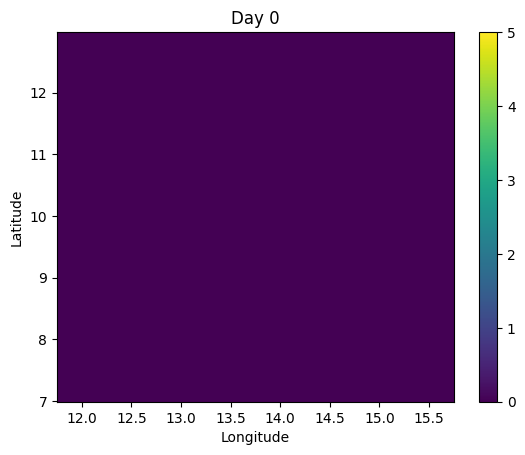

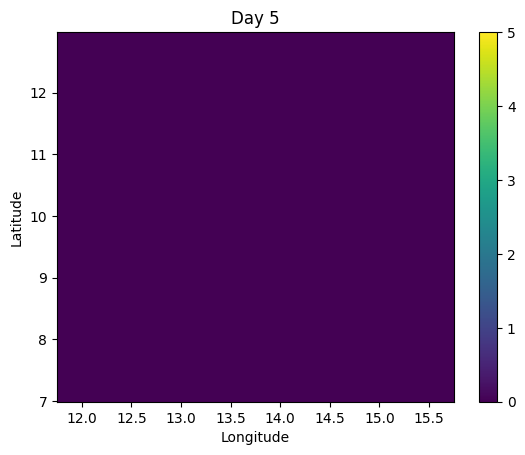

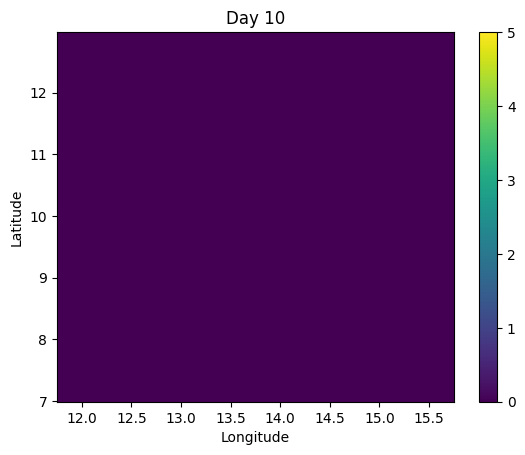

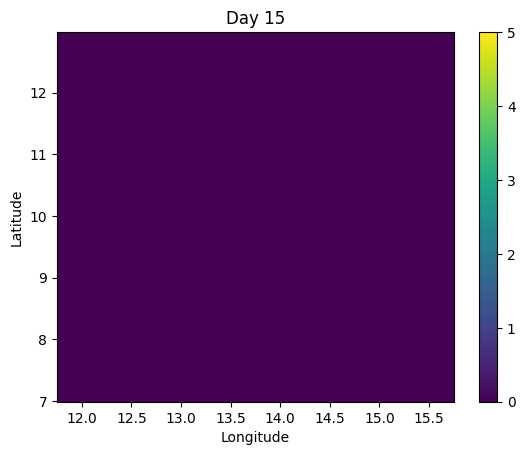

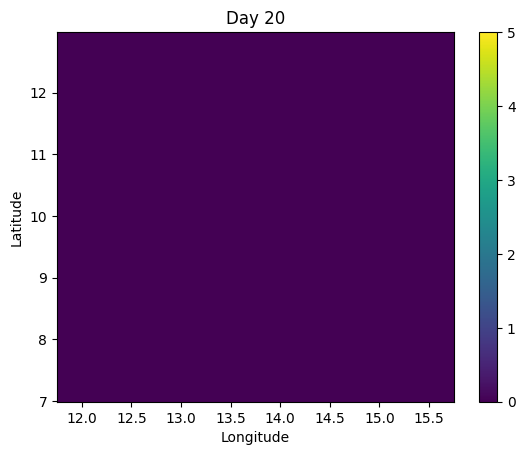

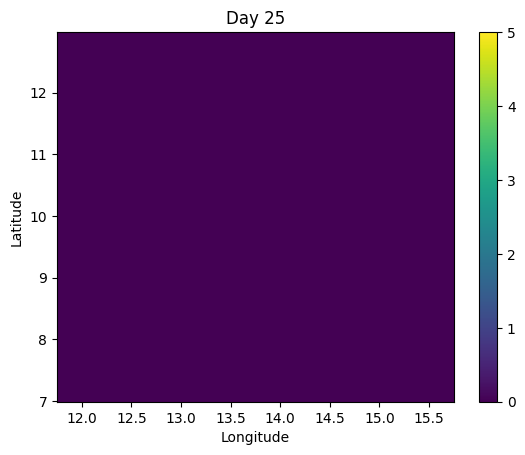

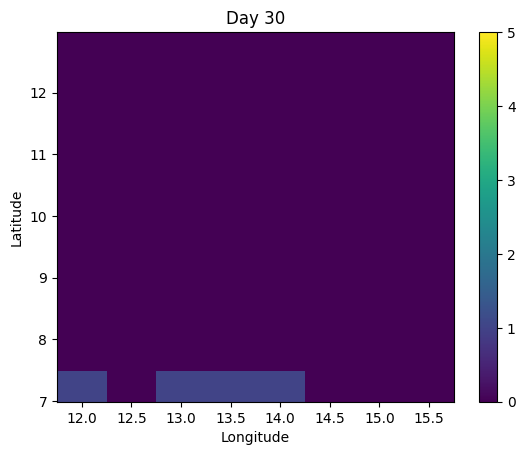

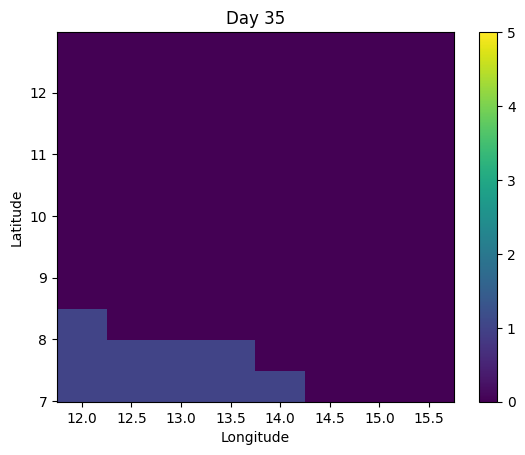

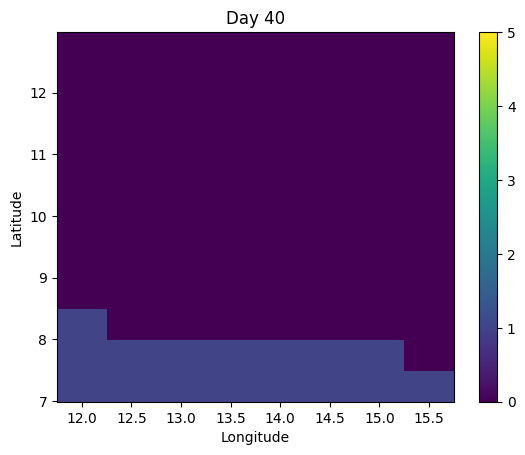

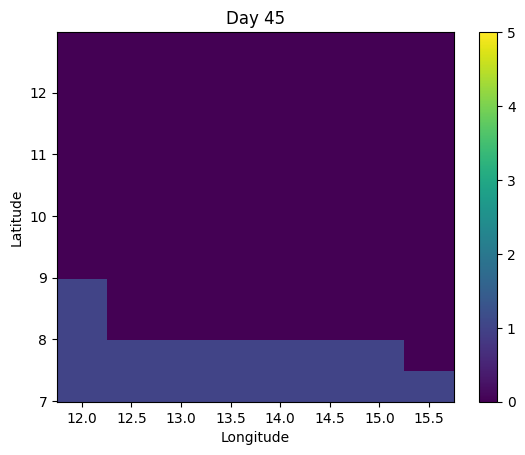

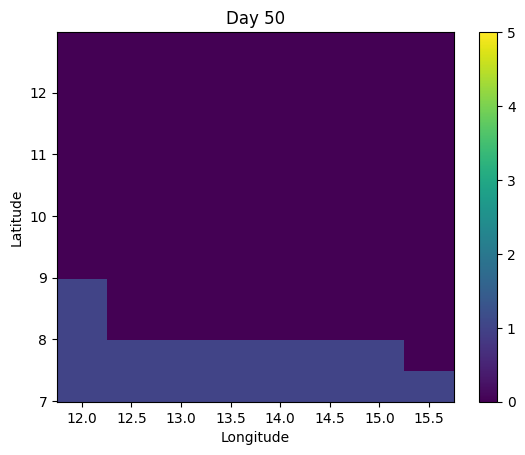

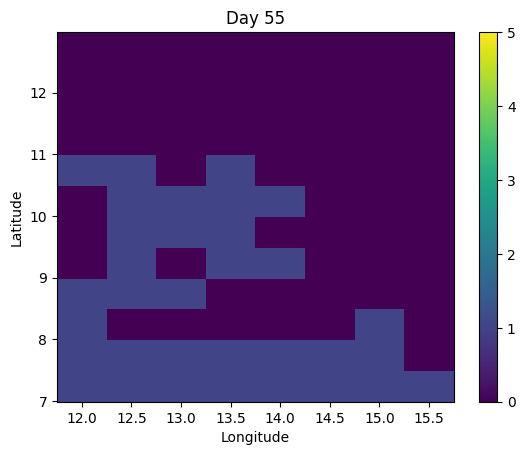

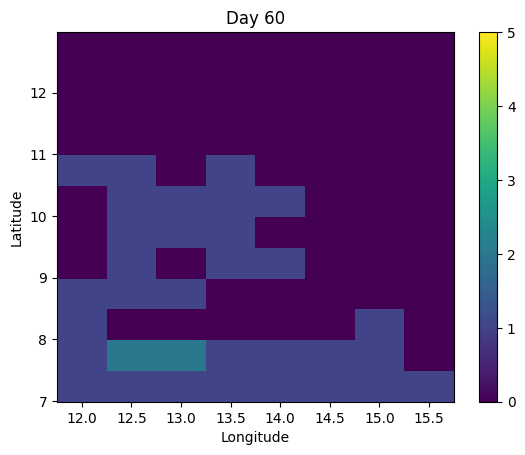

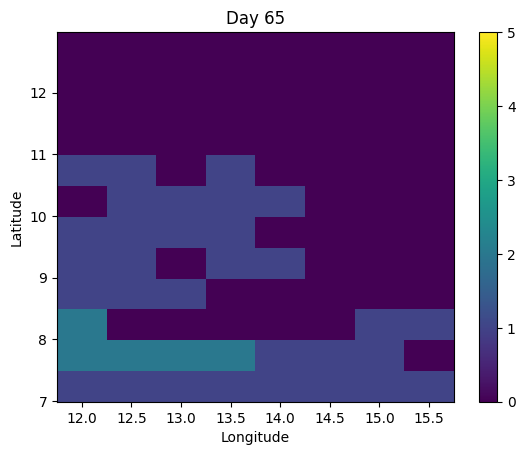

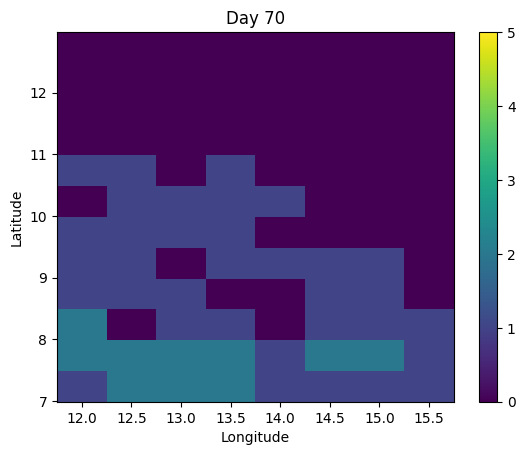

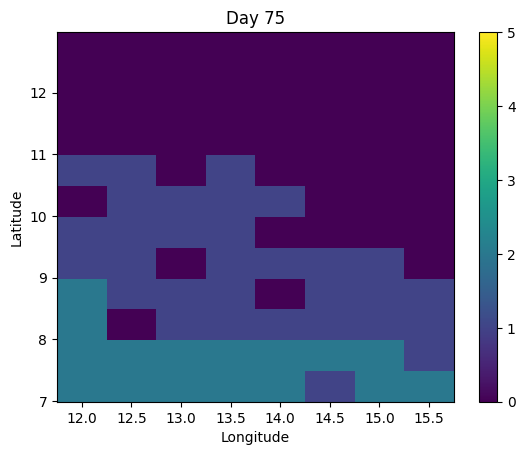

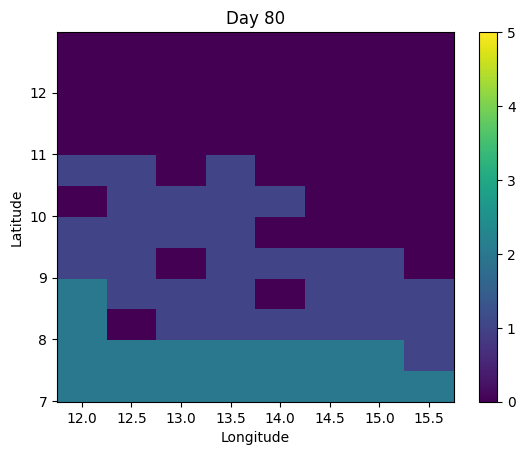

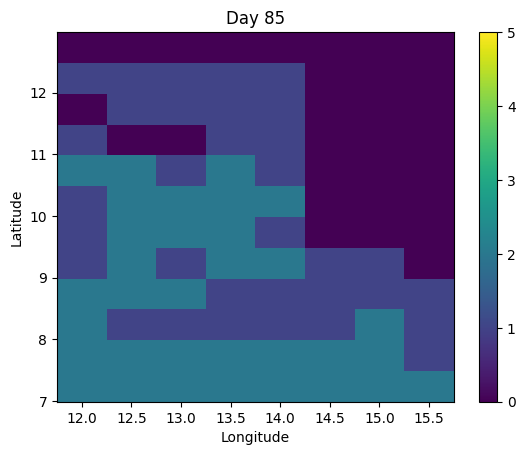

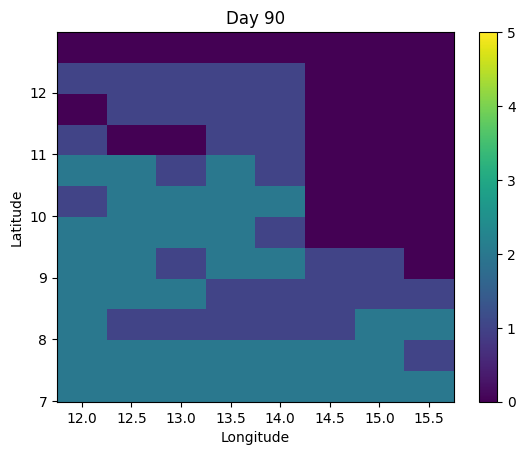

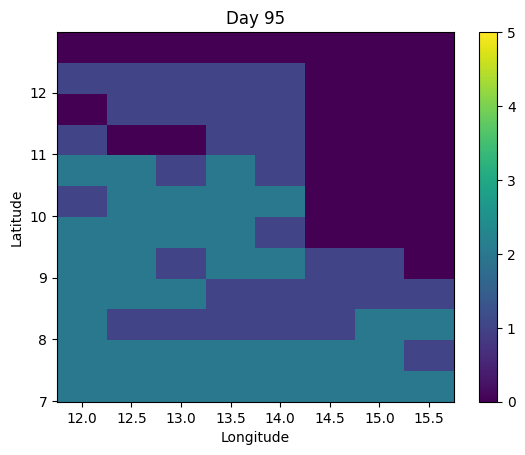

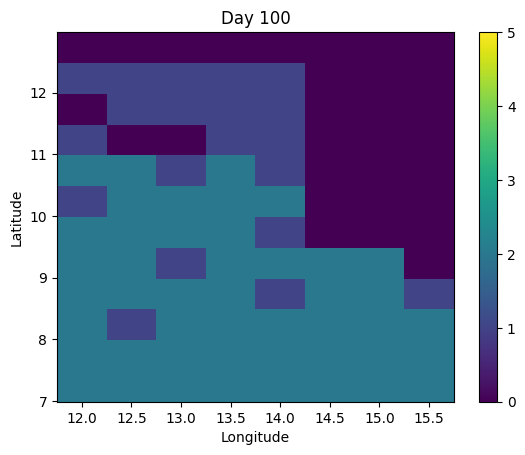

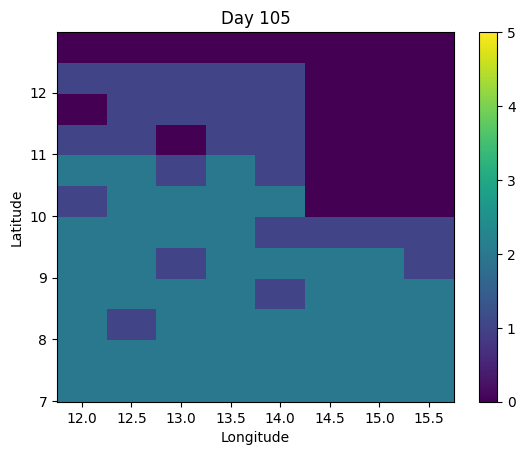

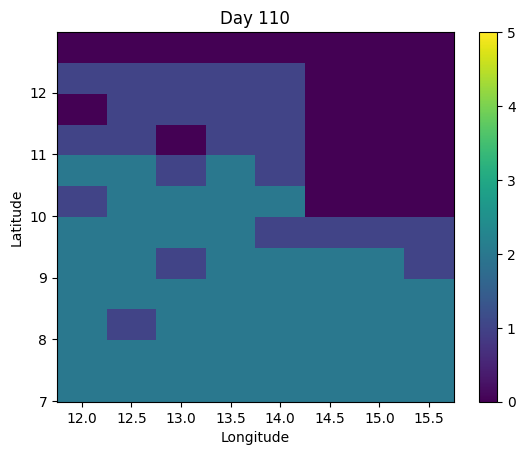

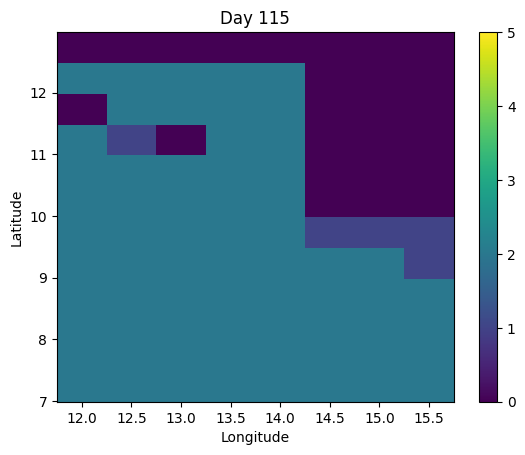

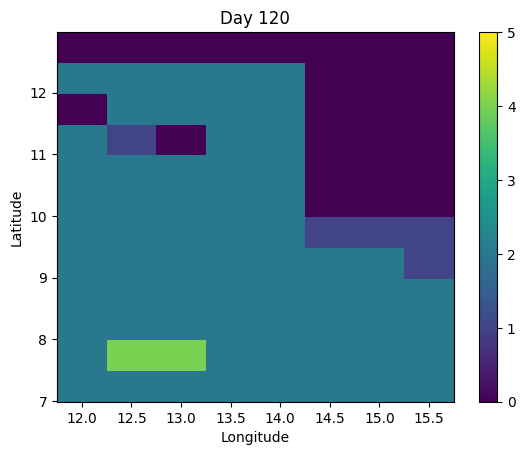

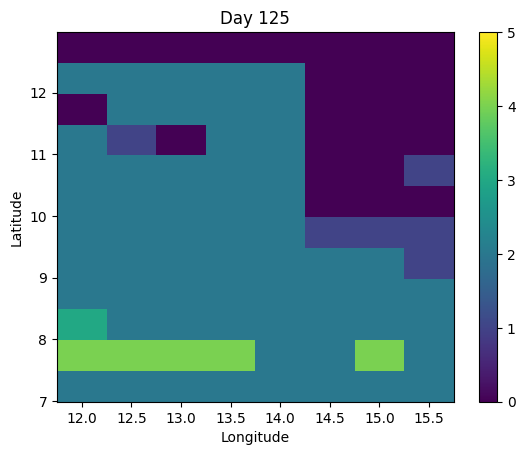

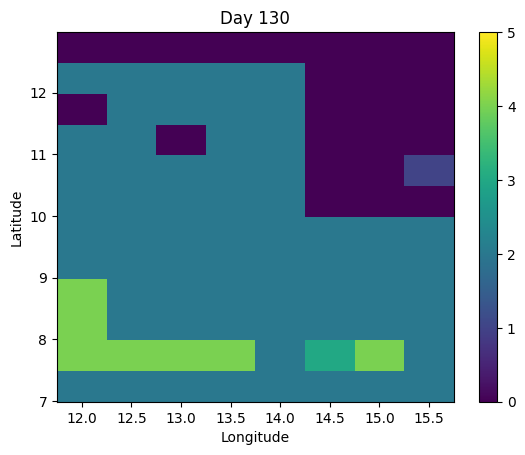

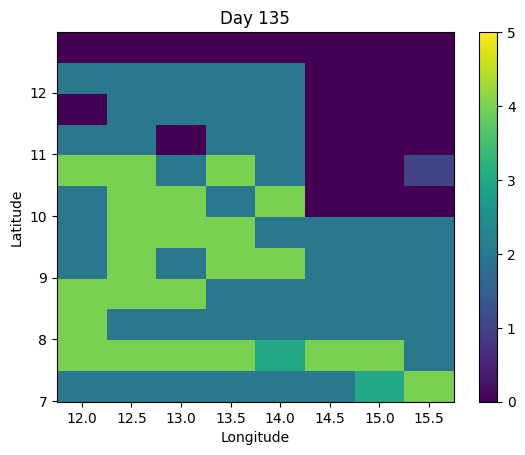

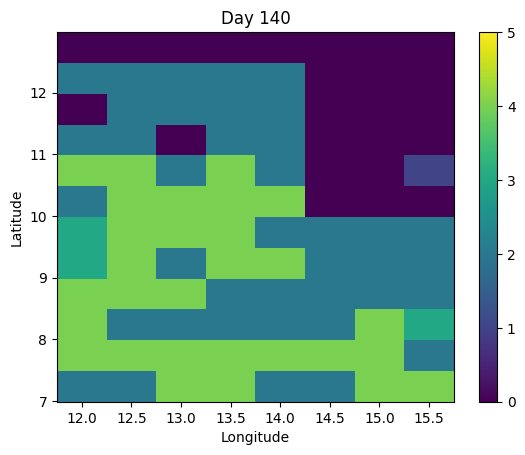

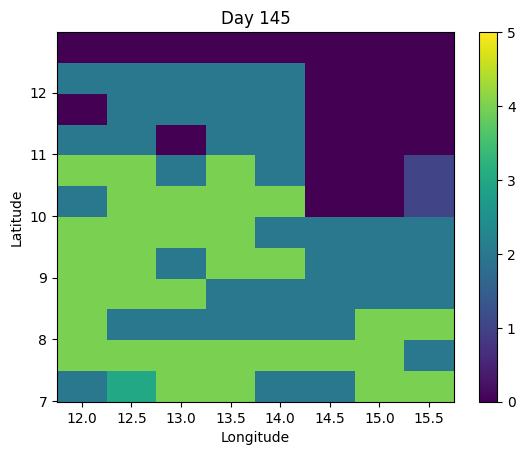

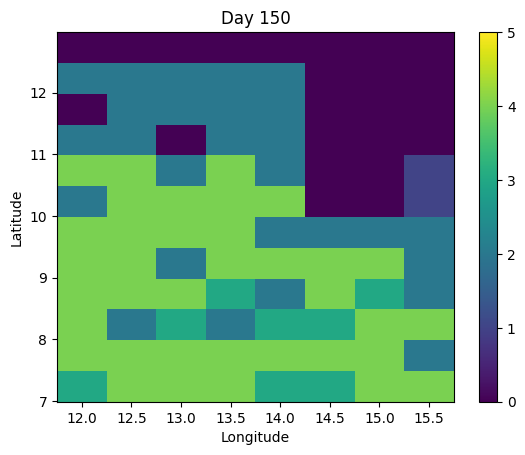

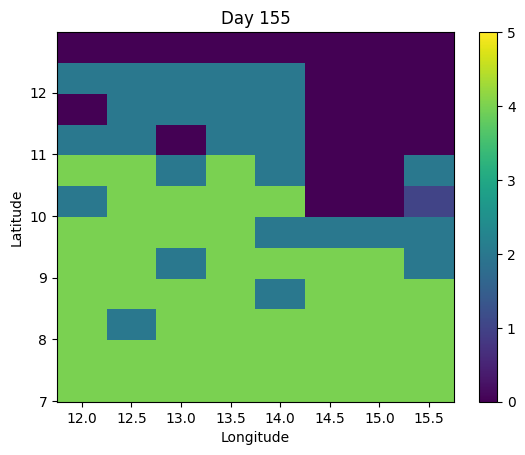

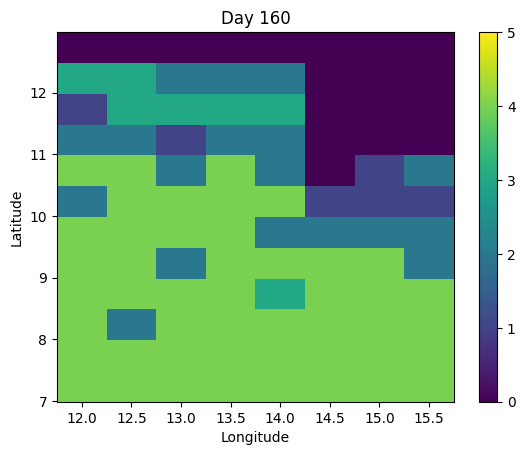

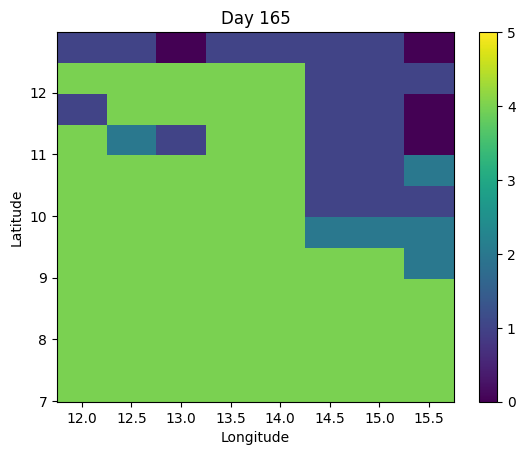

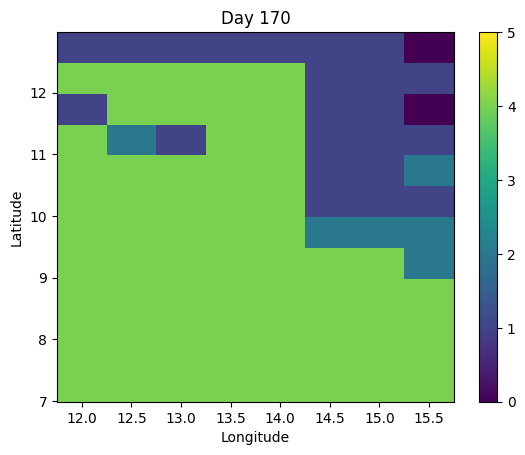

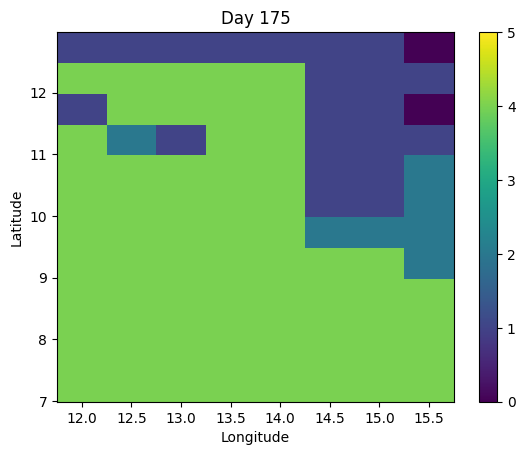

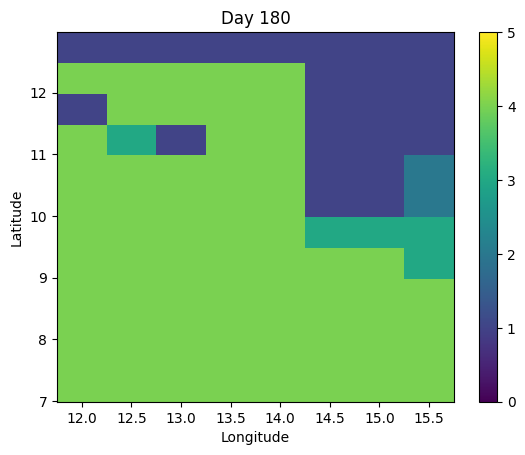

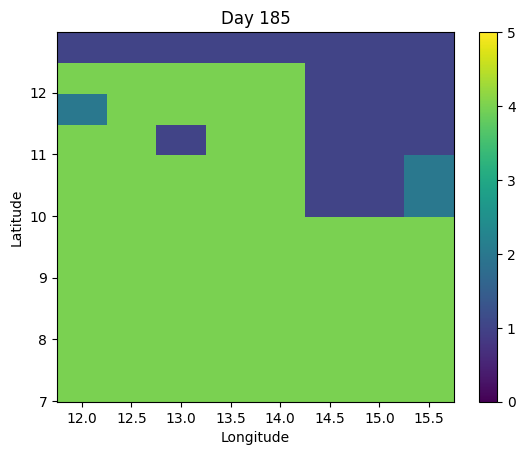

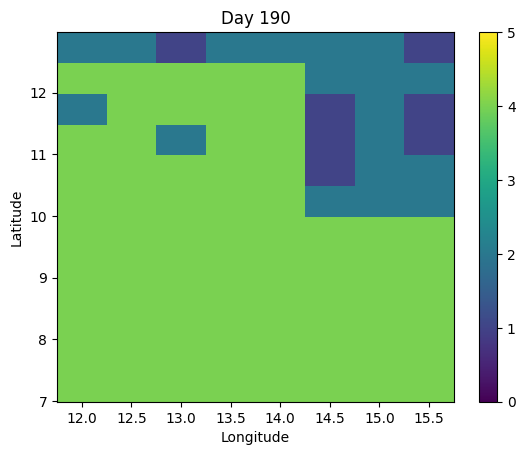

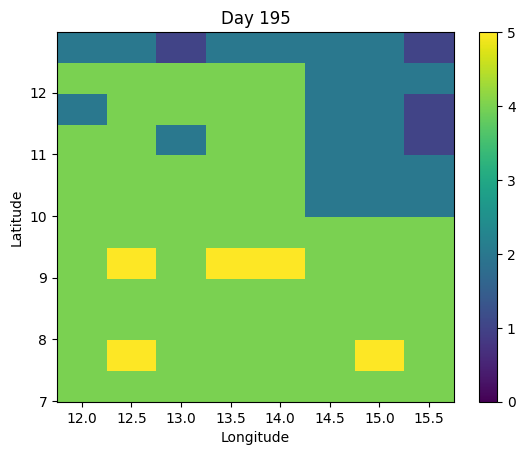

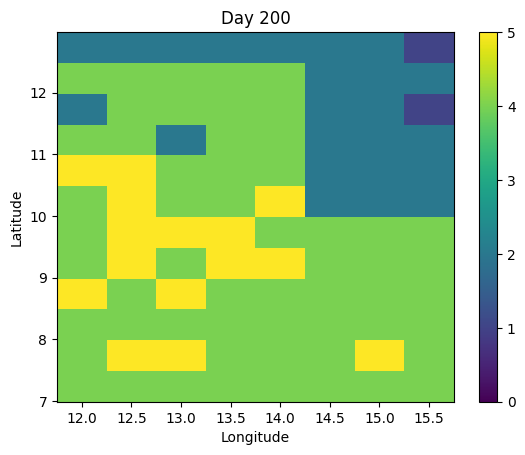

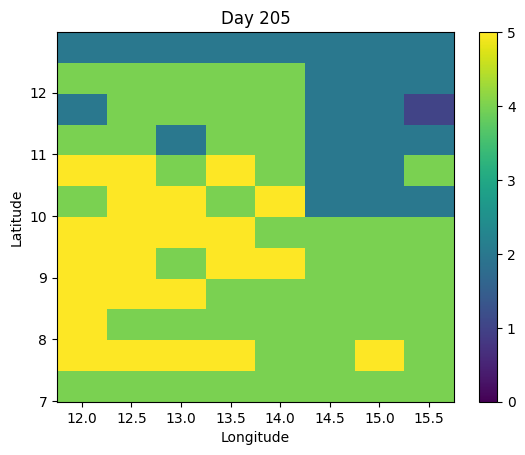

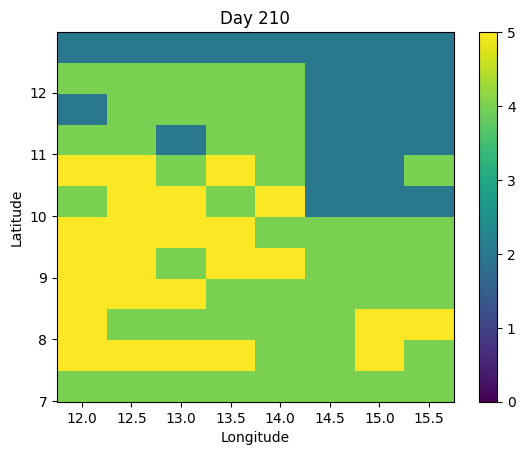

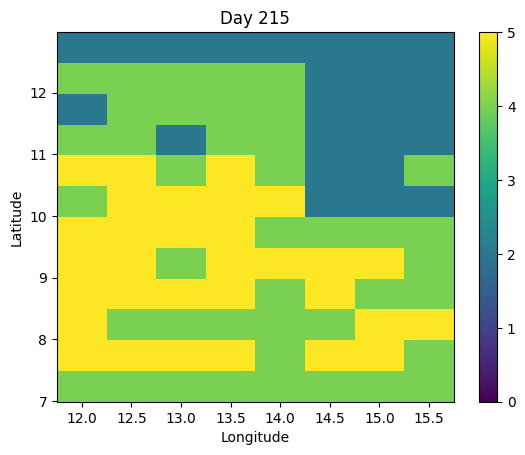

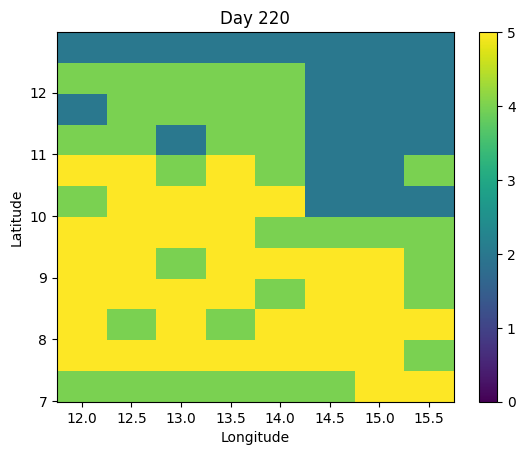

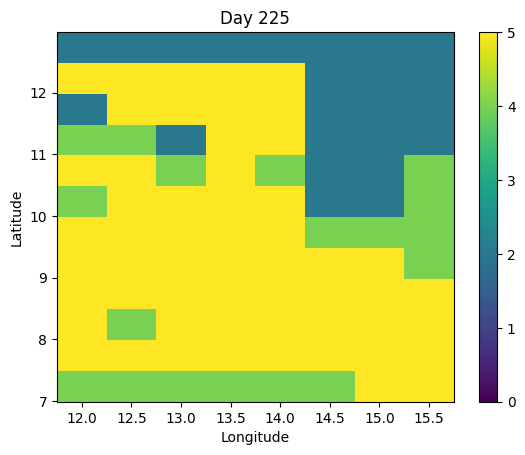

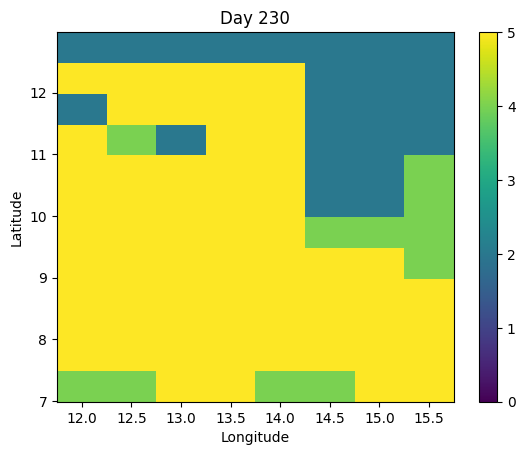

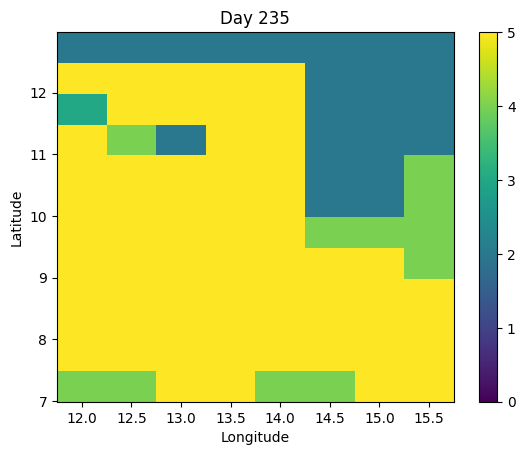

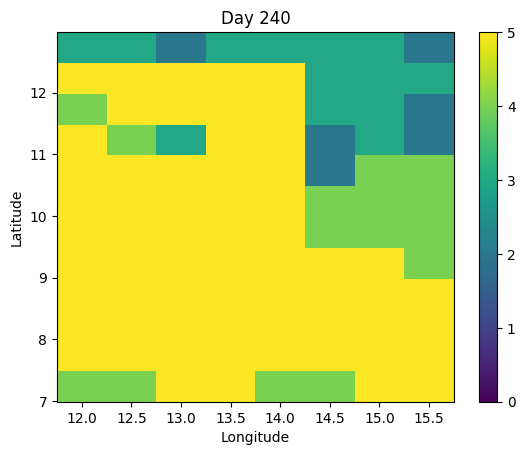

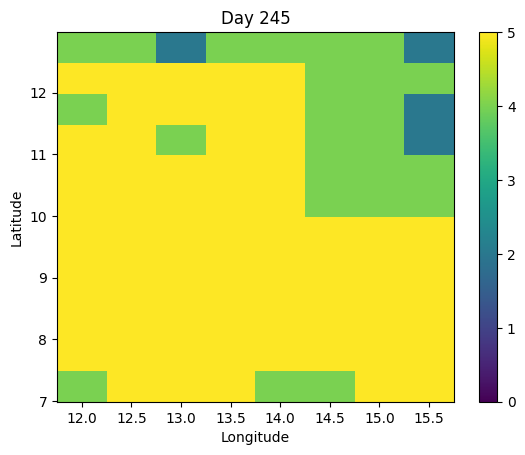

In [256]:
variable = "numPhase" # we define the variable we want to plot, here the number of phenological phase (0 to 7)
time_resolution = 5 # we will make a plot every 5 days
vmax = data[variable].max().values # we define the maximum value for the colorbar

# we loop over the time steps and plot the variable
for i in range(int(round(duration/time_resolution, 0))):
    xr.where(np.isnan(data["ru"]),np.nan,data[variable][time_resolution*i,:,:]).plot(vmin=0, vmax=vmax)
    plt.title("Day %s" % (i*time_resolution))
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.show()

### 5.2 Plotting endpoint simulated yield

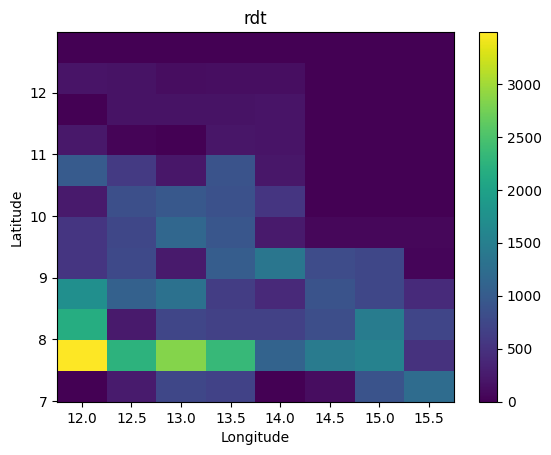

In [257]:
variable = "rdt" # we define the variable we want to plot, here the yield (rendement), in kg/ha

# we plot the variable at the last time step
xr.where(np.isnan(data["ru"]),np.nan,data[variable][-1,:,:]).plot()
plt.title("%s" % (variable))
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()